# Tabular foundation models: inference test (CPU)

Runs three tabular foundation models, each with a classifier and a regressor, on 8 small datasets
(4 classification, 4 regression). None of them is trained on this data in the usual sense: the training rows are
given to the model as **context**, and it predicts the test rows in one forward pass (**in-context learning**).
A classic gradient-boosted tree model is included as a baseline.

| Model | Package / weights | Size | Runs on CPU? |
|---|---|---|---|
| **TabICLv2** classifier + regressor | `tabicl` · `tabicl-{classifier,regressor}-v2-20260212.ckpt` | ~28M params | **yes**, seconds per dataset |
| **TabDPT v1.2** classifier + regressor | `tabdpt==1.2.0` · `Layer6/TabDPT` `tabdpt1_2.safetensors` | ~64M params | **yes**, seconds to tens of seconds (`compile=False`, since there is no C++ compiler here) |
| **Mitra (v1)** classifier + regressor | `autogluon.tabular[mitra]` · `autogluon/mitra-{classifier,regressor}` | ~76M params | **yes, but slow**: minutes per dataset. AutoGluon itself warns CPU is 12–63× slower than a GPU. |
| HistGradientBoosting (baseline) | scikit-learn | — | yes, under a second |

**Scores:**
- **Classification:** accuracy (higher is better), **ROC AUC** (how well the probabilities rank the classes; 1.0 is perfect, 0.5 is random) and **log loss** (penalises confident wrong probabilities; lower is better).
- **Regression:** **R²** (1.0 is perfect, 0 is "always guess the average") and **RMSE/MAE** (typical error in the target's units).
  For TabICLv2's quantiles, **80% coverage** is the % of true values inside its 0.1–0.9 range; the ideal is about 80%.

In [1]:
import gc, json, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import accuracy_score, log_loss, mean_absolute_error, r2_score, roc_auc_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

warnings.filterwarnings("ignore")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(max(1, torch.get_num_threads()))
print("device:", DEVICE, "| torch", torch.__version__, "| threads", torch.get_num_threads())

DATA = Path("data")
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

device: cpu | torch 2.13.0+cpu | threads 4


## Settings

In [2]:
TEST_SIZE = 0.2
SEED = 0
N_ENSEMBLES = 8      # TabICLv2 n_estimators / TabDPT n_ensembles: averaged shuffled views of the table
# Mitra is slow on CPU (minutes per dataset), so by default it runs on the smaller datasets only.
# Set MITRA_DATASETS = "all" on a GPU machine, or if you have time to wait.
MITRA_DATASETS = ["breast_cancer", "wine", "credit_risk", "diabetes"]

## The 8 datasets

| Dataset | Task | Predict | Notes |
|---|---|---|---|
| breast_cancer | binary | malignant / benign | 30 numeric measurements, easy |
| wine | 3 classes | grape cultivar | only 178 rows |
| adult_income | binary | income >50K | census data, 8 text-category columns, 2,000-row sample |
| credit_risk | binary | good / bad credit | 13 text-category columns, hard |
| diabetes | regression | disease progression | 442 rows, noisy |
| california_housing | regression | median house value (USD) | 2,000-row sample |
| abalone | regression | age (rings) | 1 categorical column |
| house_prices | regression | sale price (USD) | 79 features, 43 categorical, many missing values |

Each one is split **80% context ("training") / 20% test**, with the same split for every model.

In [3]:
META = json.loads((DATA / "meta.json").read_text())
DATASETS = {}
for name, m in META.items():
    df = pd.read_csv(DATA / f"{name}.csv")
    y = df.pop("target")
    strat = y if m["task"] == "classification" else None
    Xtr, Xte, ytr, yte = train_test_split(df, y, test_size=TEST_SIZE, random_state=SEED, stratify=strat)
    DATASETS[name] = dict(task=m["task"], Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte)

display(pd.DataFrame(META).T[["task", "rows", "features", "categorical", "missing_cells", "description"]])
print("example rows (credit_risk):")
display(DATASETS["credit_risk"]["Xtr"].head(3))

,task,rows,features,categorical,missing_cells,description
breast_cancer,classification,569,30,0,0,tumour measurements -> malignant / benign
wine,classification,178,13,0,0,chemical analysis -> 3 grape cultivars
adult_income,classification,2000,14,8,275,census record -> income >50K or <=50K
credit_risk,classification,1000,20,13,0,loan applicant -> good / bad credit risk
diabetes,regression,442,10,0,0,patient measurements -> disease progression af...
california_housing,regression,2000,8,0,0,census block -> median house value (USD)
abalone,regression,2000,8,1,0,shell measurements -> age in rings
house_prices,regression,1460,79,43,6965,Ames house features -> sale price (USD)


example rows (credit_risk):


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
355,0<=X<200,24,existing paid,new car,1246,<100,<1,4,male single,none,2,real estate,23,stores,own,1,unskilled resident,1,none,yes
661,<0,12,existing paid,new car,900,no known savings,1<=X<4,4,male mar/wid,none,2,car,23,none,own,1,skilled,1,none,yes
300,no checking,6,existing paid,new car,672,<100,unemployed,1,female div/dep/mar,none,4,real estate,54,none,own,1,unemp/unskilled non res,1,yes,yes


## Helpers: encoding, scoring, bookkeeping

- **TabICLv2** takes the raw pandas table (text categories and missing values included) and encodes it internally.
- **TabDPT** and **Mitra** need numbers, so text categories are turned into integer codes (`OrdinalEncoder`).
  TabDPT fills missing values itself; for Mitra they are filled with the column mean.
- **Class labels** are integer codes `0..k-1` in sorted order, so every model's probabilities line up.

In [4]:
def numeric(name, fill_missing=False):
    d = DATASETS[name]
    Xtr, Xte = d["Xtr"].copy(), d["Xte"].copy()
    cats = Xtr.select_dtypes(exclude="number").columns
    if len(cats):
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=np.nan)
        Xtr[cats] = enc.fit_transform(Xtr[cats].astype(str).where(Xtr[cats].notna()))
        Xte[cats] = enc.transform(Xte[cats].astype(str).where(Xte[cats].notna()))
    Xtr, Xte = Xtr.astype(float), Xte.astype(float)
    if fill_missing:
        mu = Xtr.mean()
        Xtr, Xte = Xtr.fillna(mu), Xte.fillna(mu)
    return Xtr.to_numpy(), Xte.to_numpy()

def classes(name):
    return np.array(sorted(DATASETS[name]["ytr"].unique()))

def codes(name, which="ytr"):
    return np.searchsorted(classes(name), DATASETS[name][which].to_numpy()).astype(np.int64)

PRED, TIMES = {}, {}   # PRED[model][dataset] = {"pred": ..., "proba": ..., "q10": ..., "q90": ...}

def record(model, name, seconds, **out):
    PRED.setdefault(model, {})[name] = out
    TIMES.setdefault(model, {})[name] = seconds

def scores(model, name):
    d, p = DATASETS[name], PRED[model][name]
    if d["task"] == "classification":
        y = codes(name, "yte"); proba = np.clip(p["proba"], 1e-7, 1); proba = proba / proba.sum(1, keepdims=True)
        auc = roc_auc_score(y, proba[:, 1]) if proba.shape[1] == 2 else roc_auc_score(y, proba, multi_class="ovr")
        return {"accuracy": accuracy_score(y, proba.argmax(1)), "roc_auc": auc, "log_loss": log_loss(y, proba, labels=range(proba.shape[1]))}
    y = d["yte"].to_numpy(float)
    s = {"r2": r2_score(y, p["pred"]), "rmse": root_mean_squared_error(y, p["pred"]), "mae": mean_absolute_error(y, p["pred"])}
    if "q10" in p:
        s["coverage_80"] = 100 * np.mean((y >= p["q10"]) & (y <= p["q90"]))
    return s

def show_model(model):
    for task in ["classification", "regression"]:
        rows = {n: {**scores(model, n), "seconds": TIMES[model][n]} for n in PRED[model] if DATASETS[n]["task"] == task}
        if rows:
            print(f"{model} · {task}")
            display(pd.DataFrame(rows).T.round(3))

def free(*objs):
    for o in objs: del o
    gc.collect()

## Baseline: HistGradientBoosting (scikit-learn)

> Not a foundation model. This is a classic **gradient-boosted decision tree** model, the same family as LightGBM and XGBoost,
> trained normally on the 80% split with default settings and no tuning. It handles text categories and missing values natively.
> It is the reference point: the foundation models should match or beat it without any training.

In [5]:
for name, d in DATASETS.items():
    Xtr = d["Xtr"].apply(lambda c: c.astype("category") if c.dtype == object else c)
    Xte = d["Xte"].apply(lambda c: c.astype("category") if c.dtype == object else c)
    for c in Xtr.select_dtypes("category"):
        Xte[c] = pd.Categorical(Xte[c], categories=Xtr[c].cat.categories)
    t = time.time()
    if d["task"] == "classification":
        m = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=SEED).fit(Xtr, codes(name))
        record("HistGB", name, time.time() - t, proba=m.predict_proba(Xte))
    else:
        m = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=SEED).fit(Xtr, d["ytr"])
        record("HistGB", name, time.time() - t, pred=m.predict(Xte))
show_model("HistGB")

HistGB · classification


,accuracy,roc_auc,log_loss,seconds
breast_cancer,0.965,0.990,0.126,0.139
wine,0.972,1.000,0.062,0.101
adult_income,0.835,0.883,0.407,0.171
credit_risk,0.805,0.826,0.496,0.151


HistGB · regression


,r2,rmse,mae,seconds
diabetes,0.162,65.563,50.997,0.066
california_housing,0.782,52420.632,36809.514,0.140
abalone,0.508,2.227,1.597,0.140
house_prices,0.854,31787.747,16779.746,0.293


## 1. TabICLv2 (Inria SODA team)

> **What it does:** a small transformer (~28M parameters) pre-trained only on millions of **synthetic** tables.
> It reads a table in 3 stages: **down each column** (what the values look like), **across each row**
> (compressing the row into one vector), then **from each test row to all labelled rows** (in-context learning).
> The classifier predicts class probabilities. The regressor predicts **999 quantiles**, so you get an uncertainty range, not just one number.
>
> | | Classifier (`TabICLClassifier`) | Regressor (`TabICLRegressor`) |
> |---|---|---|
> | **Input** | `X`: pandas DataFrame or array (text categories and missing values OK) + `y` labels | same, with numeric `y` |
> | **Output** | `predict` → labels; `predict_proba` → `(n_rows, n_classes)` probabilities | `predict` → mean per row; `predict(..., output_type="quantiles", alphas=[0.1, 0.5, 0.9])` → `(n_rows, 3)` |
> | **Needs from you** | nothing besides the data. No tuning. `fit` just stores the data (and downloads the checkpoint the first time). | same |

In [6]:
from tabicl import TabICLClassifier, TabICLRegressor

for name, d in DATASETS.items():
    t = time.time()
    if d["task"] == "classification":
        m = TabICLClassifier(n_estimators=N_ENSEMBLES, random_state=SEED, device=DEVICE)
        m.fit(d["Xtr"], d["ytr"])
        proba = m.predict_proba(d["Xte"])
        proba = proba[:, np.searchsorted(m.classes_, classes(name))]   # align to sorted class order
        record("TabICLv2", name, time.time() - t, proba=proba)
    else:
        m = TabICLRegressor(n_estimators=N_ENSEMBLES, random_state=SEED, device=DEVICE)
        m.fit(d["Xtr"], d["ytr"])
        q = m.predict(d["Xte"], output_type="quantiles", alphas=[0.1, 0.5, 0.9])
        record("TabICLv2", name, time.time() - t, pred=m.predict(d["Xte"]), q10=q[:, 0], q50=q[:, 1], q90=q[:, 2])
    print(f"{name}: {TIMES['TabICLv2'][name]:.1f}s", flush=True)
    free(m)
show_model("TabICLv2")

breast_cancer: 6.3s


wine: 1.5s


adult_income: 20.8s


credit_risk: 11.6s


diabetes: 4.0s


california_housing: 19.0s


... (2 outputs left out)

TabICLv2 · classification


,accuracy,roc_auc,log_loss,seconds
breast_cancer,0.965,0.994,0.081,6.302
wine,1.000,1.000,0.001,1.528
adult_income,0.845,0.908,0.326,20.813
credit_risk,0.795,0.840,0.441,11.574


TabICLv2 · regression


,r2,rmse,mae,coverage_80,seconds
diabetes,0.352,57.631,44.112,78.652,3.979
california_housing,0.854,42957.181,27980.279,80.250,19.039
abalone,0.578,2.062,1.448,80.500,18.722
house_prices,0.827,34549.446,15186.789,78.082,46.223


## 2. TabDPT v1.2 (Layer 6)

> **What it does:** a transformer (~64M parameters) that, unlike the other two, is pre-trained on **real** tables
> (a large collection of public datasets) using self-supervised tasks. For each test row it uses the training rows as context.
> On big tables it can pick the most similar rows (`context_reduction="retrieval"`) instead of a random sample.
>
> | | Classifier (`TabDPTClassifier`) | Regressor (`TabDPTRegressor`) |
> |---|---|---|
> | **Input** | numeric array `X` (text categories must be encoded first; missing values OK) + integer labels `y` | numeric array `X` + numeric `y` |
> | **Output** | `ensemble_predict_proba(X, n_ensembles=8)` → `(n_rows, n_classes)` probabilities | `predict(X, n_ensembles=8)` → one number per row. Version 1.2 has **no** uncertainty range. |
> | **Needs from you** | encode text categories as numbers. `compile=False` on machines without a C++ compiler. | same |

In [7]:
from tabdpt import TabDPTClassifier, TabDPTRegressor

for name, d in DATASETS.items():
    Xtr, Xte = numeric(name)
    t = time.time()
    if d["task"] == "classification":
        m = TabDPTClassifier(device=DEVICE, compile=False, verbose=False)
        m.fit(Xtr, codes(name))
        record("TabDPT-v1.2", name, time.time() - t, proba=m.ensemble_predict_proba(Xte, n_ensembles=N_ENSEMBLES, seed=SEED))
    else:
        m = TabDPTRegressor(device=DEVICE, compile=False, verbose=False)
        m.fit(Xtr, d["ytr"].to_numpy(float))
        record("TabDPT-v1.2", name, time.time() - t, pred=m.predict(Xte, n_ensembles=N_ENSEMBLES, seed=SEED))
    print(f"{name}: {TIMES['TabDPT-v1.2'][name]:.1f}s", flush=True)
    free(m)
show_model("TabDPT-v1.2")

breast_cancer: 1.0s


wine: 0.9s


adult_income: 0.7s


credit_risk: 0.8s


diabetes: 0.8s


california_housing: 0.9s


... (2 outputs left out)

TabDPT-v1.2 · classification


,accuracy,roc_auc,log_loss,seconds
breast_cancer,0.974,0.994,0.081,0.997
wine,1.000,1.000,0.004,0.896
adult_income,0.835,0.902,0.335,0.729
credit_risk,0.780,0.848,0.443,0.786


TabDPT-v1.2 · regression


,r2,rmse,mae,seconds
diabetes,0.337,58.317,44.600,0.759
california_housing,0.846,44163.673,30465.324,0.858
abalone,0.583,2.049,1.435,0.847
house_prices,0.933,21447.357,13667.560,0.758


## 3. Mitra v1 (Amazon AutoGluon)

> **What it does:** a 12-layer transformer (~76M parameters) with **2D attention**: it attends across rows (comparing examples)
> and across columns (comparing features). It is pre-trained on a **mix of synthetic data generators**:
> structural causal models plus tree-based generators (decision trees, random forests, boosting), which helps on
> real tables where tree-like rules are common. It can optionally be **fine-tuned** for a few steps on your data (off here).
>
> | | Classifier (`MitraClassifier`) | Regressor (`MitraRegressor`) |
> |---|---|---|
> | **Input** | numeric `X` (encoded categories, no missing values) + integer labels `y` (int64) | numeric `X` + numeric `y` |
> | **Output** | `predict_proba` → `(n_rows, n_classes)` probabilities | `predict` → one number per row. v1 has **no** uncertainty range (v2 adds a 1,000-bin distribution). |
> | **Needs from you** | encode categories, fill missing values. **A GPU** for anything beyond small tables. | same |
>
> **How it's normally used:** inside AutoGluon, `TabularPredictor(label="target").fit(df, hyperparameters={"MITRA": {"fine_tune": False}})`,
> which also handles encoding. This notebook calls AutoGluon's scikit-learn-style `MitraClassifier`/`MitraRegressor` directly,
> because `TabularPredictor` also scores the model on a held-out validation split, which doubles the already slow CPU time.

In [8]:
from autogluon.tabular.models.mitra.sklearn_interface import MitraClassifier, MitraRegressor

run_on = list(DATASETS) if MITRA_DATASETS == "all" else MITRA_DATASETS
for name in run_on:
    d = DATASETS[name]
    Xtr, Xte = numeric(name, fill_missing=True)
    t = time.time()
    if d["task"] == "classification":
        m = MitraClassifier(device=DEVICE, fine_tune=False, n_estimators=1, verbose=False)
        m.fit(Xtr, codes(name))
        record("Mitra-v1", name, time.time() - t, proba=np.asarray(m.predict_proba(Xte)))
    else:
        m = MitraRegressor(device=DEVICE, fine_tune=False, n_estimators=1, verbose=False)
        m.fit(Xtr, d["ytr"].to_numpy(float))
        record("Mitra-v1", name, time.time() - t, pred=np.asarray(m.predict(Xte)).ravel())
    print(f"{name}: {TIMES['Mitra-v1'][name]:.1f}s", flush=True)
    free(m)
show_model("Mitra-v1")

breast_cancer: 47.1s


wine: 11.1s


credit_risk: 57.0s


diabetes: 14.0s


Mitra-v1 · classification


,accuracy,roc_auc,log_loss,seconds
breast_cancer,0.982,0.995,0.075,47.131
wine,1.000,1.000,0.034,11.109
credit_risk,0.805,0.846,0.448,56.986


Mitra-v1 · regression


,r2,rmse,mae,seconds
diabetes,0.317,59.189,43.964,13.965


## 4. Summary

The main score is **accuracy** for classification and **R²** for regression; the best model per dataset is in **bold**.
`NaN` means the model wasn't run on that dataset (Mitra is limited to the small ones by default).

In [9]:
MODELS = ["HistGB", "TabICLv2", "TabDPT-v1.2", "Mitra-v1"]
MAIN = {"classification": "accuracy", "regression": "r2"}
tables = {}
for task, metric in MAIN.items():
    names = [n for n, d in DATASETS.items() if d["task"] == task]
    tables[task] = pd.DataFrame({m: {n: scores(m, n)[metric] if n in PRED.get(m, {}) else np.nan for n in names} for m in MODELS})
    print(f"{task}: {metric} (higher is better)")
    display(tables[task].style.format("{:.3f}", na_rep="—").highlight_max(axis=1, props="font-weight:bold"))

extra = []
for m in MODELS:
    for n in PRED.get(m, {}):
        extra.append({"model": m, "dataset": n, **scores(m, n), "seconds": TIMES[m][n]})
SUMMARY = pd.DataFrame(extra)
SUMMARY.round(4).to_csv(OUT / "scores.csv", index=False)

speed = pd.DataFrame({m: TIMES[m] for m in MODELS}).T
print("seconds per dataset (fit + predict, CPU)")
display(speed.round(1))

classification: accuracy (higher is better)


,HistGB,TabICLv2,TabDPT-v1.2,Mitra-v1
breast_cancer,0.965,0.965,0.974,0.982
wine,0.972,1.000,1.000,1.000
adult_income,0.835,0.845,0.835,—
credit_risk,0.805,0.795,0.780,0.805


regression: r2 (higher is better)


,HistGB,TabICLv2,TabDPT-v1.2,Mitra-v1
diabetes,0.162,0.352,0.337,0.317
california_housing,0.782,0.854,0.846,—
abalone,0.508,0.578,0.583,—
house_prices,0.854,0.827,0.933,—


seconds per dataset (fit + predict, CPU)


,breast_cancer,wine,adult_income,credit_risk,diabetes,california_housing,abalone,house_prices
HistGB,0.1,0.1,0.2,0.2,0.1,0.1,0.1,0.3
TabICLv2,6.3,1.5,20.8,11.6,4.0,19.0,18.7,46.2
TabDPT-v1.2,1.0,0.9,0.7,0.8,0.8,0.9,0.8,0.8
Mitra-v1,47.1,11.1,NaN,57.0,14.0,NaN,NaN,NaN


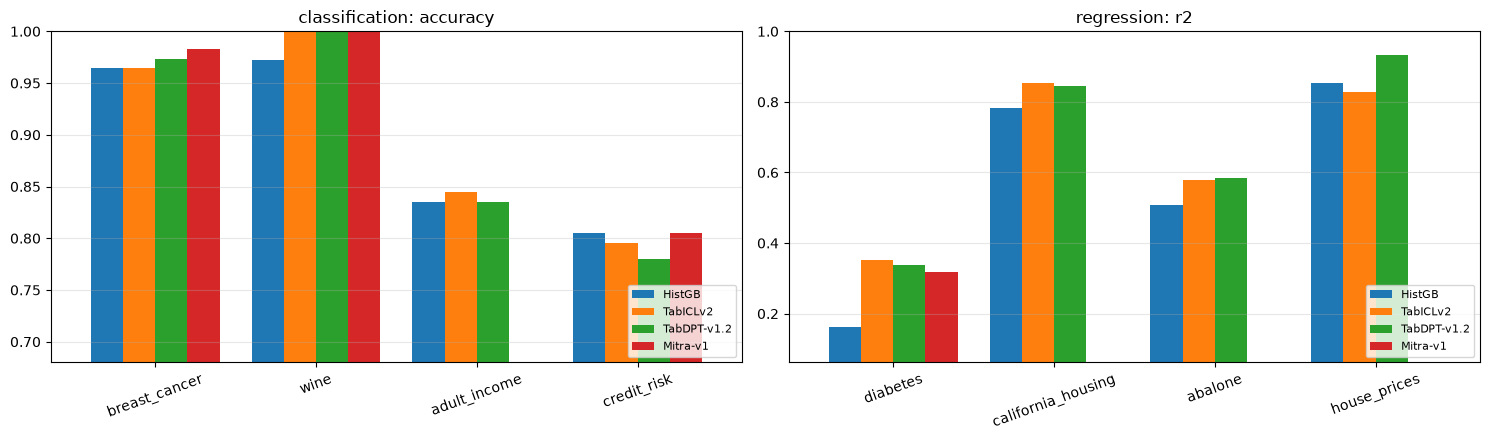

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (task, metric) in zip(axes, MAIN.items()):
    tables[task].plot.bar(ax=ax, rot=20, width=0.8)
    ax.set_title(f"{task}: {metric}"); ax.set_ylim(max(0, np.nanmin(tables[task].values) - 0.1), 1.0)
    ax.legend(fontsize=8, loc="lower right"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()


**What this run showed (CPU laptop, one 80/20 split per dataset):**
- **All three foundation models matched or beat the untuned tree baseline** on most datasets, without any training:
  - **Classification:** the models land within ~1–2 points of each other. Wine is 100% for all three foundation models. On credit risk, ROC AUC is about 0.84–0.85 vs 0.83 for HistGB.
  - **Regression:** they clearly beat HistGB on diabetes (R² 0.30–0.35 vs 0.16), California housing (0.85 vs 0.78) and abalone (0.58 vs 0.51).
- **TabDPT v1.2** was the standout on **house prices** (R² 0.93 vs 0.83–0.85). It was also by far the fastest foundation model here: **under 2 s per dataset**.
- **TabICLv2** is the only one giving an **uncertainty range**, and its 80% ranges were well calibrated: **78–81% coverage** on all 4 regression sets. It took 2–47 s per dataset.
- **Mitra v1** was as accurate as the others where it ran, but **7–55 s per small dataset on CPU** (and ~12 min for house prices in an earlier test), so use a GPU for it.
- Each dataset uses one split and a small test set, so differences of 1–2 points are within noise. Treat this as a first impression, not a benchmark.


## 5. What the outputs look like

### Classification: probabilities for 5 wine samples
Each model gives one probability per class; the predicted class is the highest one.

In [11]:
name = "wine"
rows = []
for i in range(5):
    r = {"true": DATASETS[name]["yte"].iloc[i]}
    for m in MODELS:
        if name in PRED.get(m, {}):
            p = PRED[m][name]["proba"][i]
            r[m] = "  ".join(f"{v:.2f}" for v in p) + f"  → {classes(name)[p.argmax()]}"
    rows.append(r)
print("probability columns are:", list(classes(name)))
display(pd.DataFrame(rows))

probability columns are: [np.str_('cultivar_0'), np.str_('cultivar_1'), np.str_('cultivar_2')]


,true,HistGB,TabICLv2,TabDPT-v1.2,Mitra-v1
0,cultivar_1,0.00 1.00 0.00 → cultivar_1,0.00 1.00 0.00 → cultivar_1,0.00 1.00 0.00 → cultivar_1,0.00 1.00 0.00 → cultivar_1
1,cultivar_0,1.00 0.00 0.00 → cultivar_0,1.00 0.00 0.00 → cultivar_0,1.00 0.00 0.00 → cultivar_0,0.98 0.02 0.00 → cultivar_0
2,cultivar_1,0.00 1.00 0.00 → cultivar_1,0.00 1.00 0.00 → cultivar_1,0.00 0.99 0.01 → cultivar_1,0.00 0.92 0.07 → cultivar_1
3,cultivar_0,1.00 0.00 0.00 → cultivar_0,1.00 0.00 0.00 → cultivar_0,1.00 0.00 0.00 → cultivar_0,0.99 0.01 0.00 → cultivar_0
4,cultivar_1,0.00 1.00 0.00 → cultivar_1,0.00 1.00 0.00 → cultivar_1,0.00 1.00 0.00 → cultivar_1,0.01 0.99 0.00 → cultivar_1


### Regression: predictions for 5 house prices
TabICLv2 also gives an 80% range (0.1 to 0.9 quantile). The other models give one number.

In [12]:
name = "house_prices"
p = PRED["TabICLv2"][name]
tbl = pd.DataFrame({"actual": DATASETS[name]["yte"].to_numpy()[:5],
                    "TabICLv2": p["pred"][:5], "TabICLv2 range 10%": p["q10"][:5], "TabICLv2 range 90%": p["q90"][:5]})
for m in ["TabDPT-v1.2", "Mitra-v1", "HistGB"]:
    if name in PRED.get(m, {}):
        tbl[m] = PRED[m][name]["pred"][:5]
display(tbl.round(0).astype(int))

,actual,TabICLv2,TabICLv2 range 10%,TabICLv2 range 90%,TabDPT-v1.2,HistGB
0,200624,255932,189137,325150,211044,309297
1,133000,141557,122730,160729,151017,146979
2,110000,119141,104311,133377,118885,116193
3,192000,210352,192466,229268,206941,212296
4,88000,95060,83888,105952,94974,96344


### Predicted vs actual (regression); points on the diagonal are perfect predictions

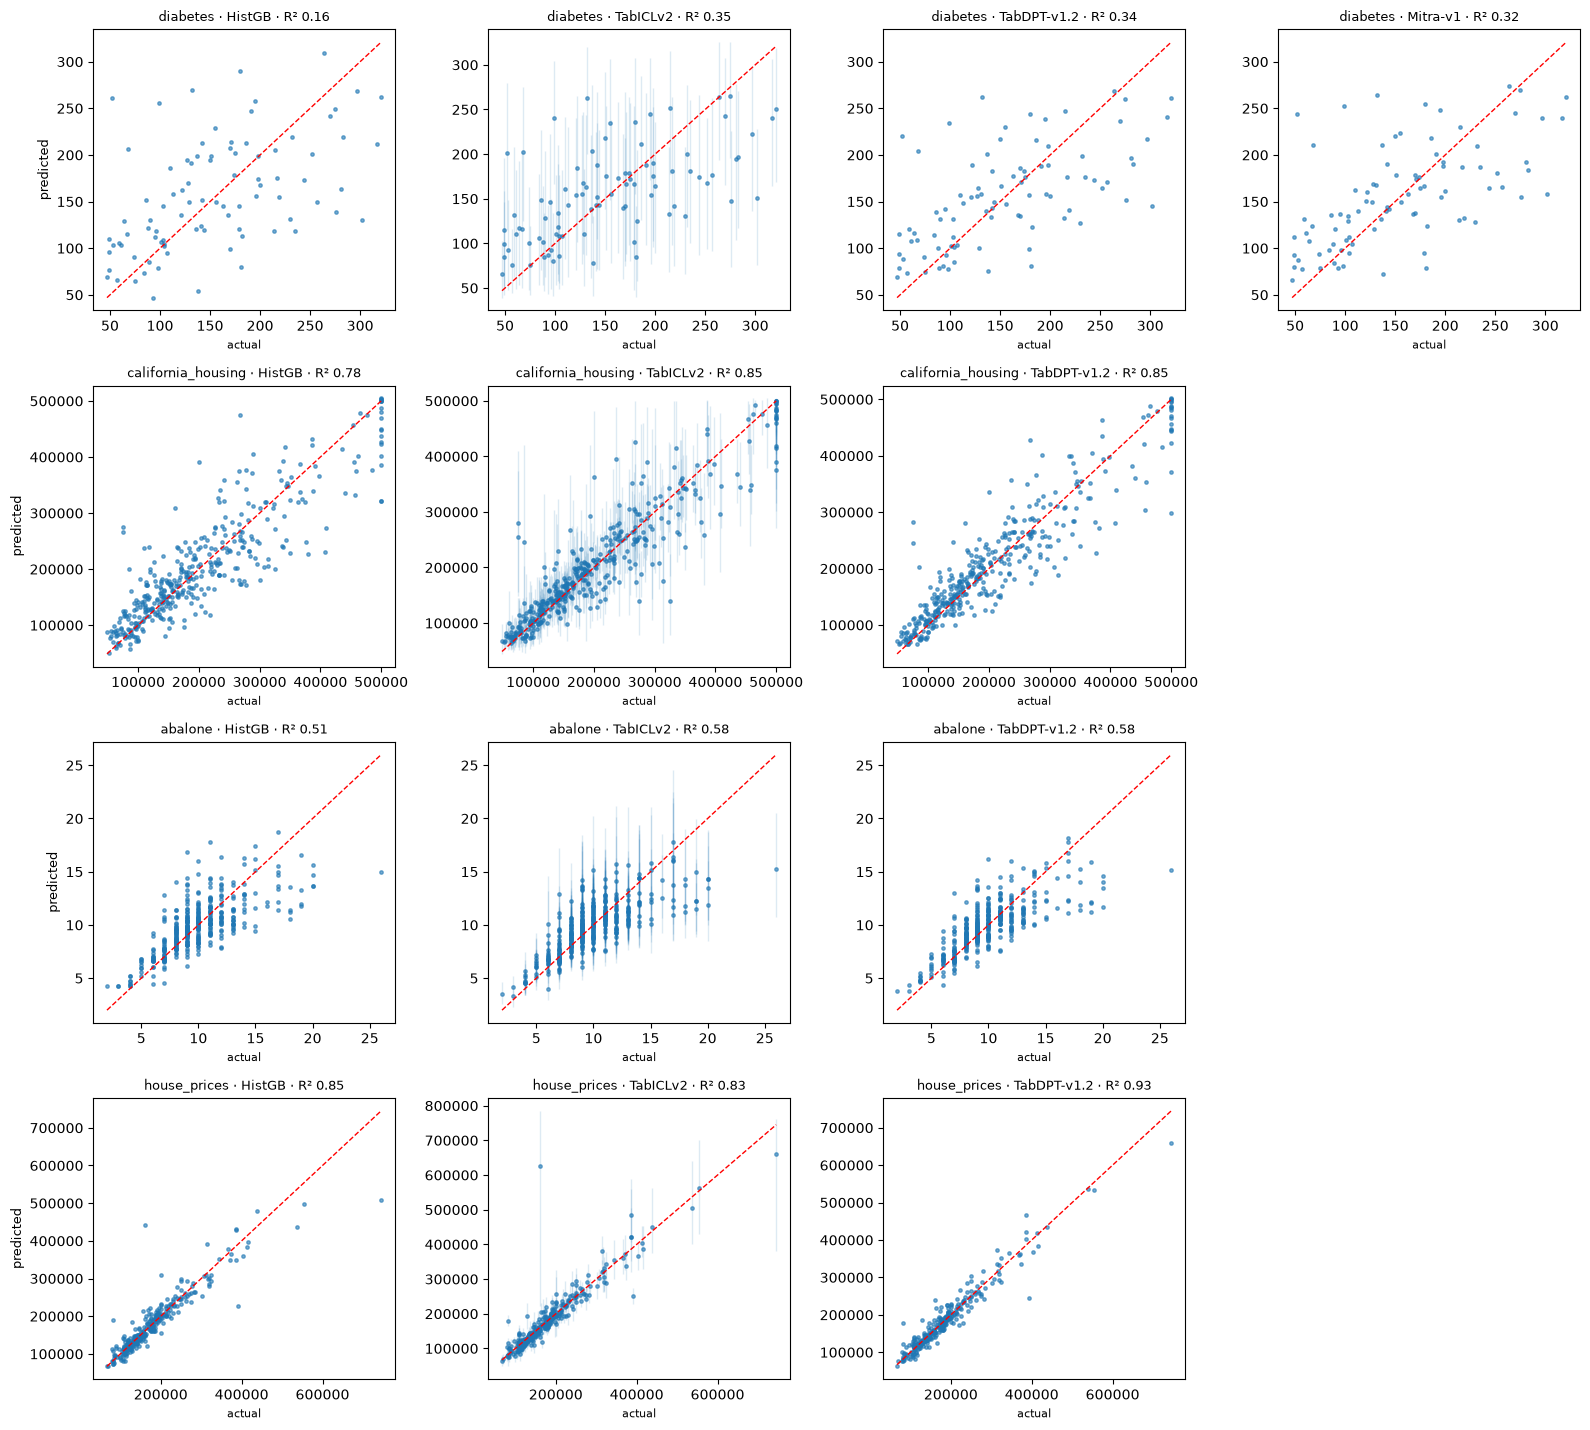

In [13]:
reg = [n for n, d in DATASETS.items() if d["task"] == "regression"]
ran = {n: [m for m in MODELS if n in PRED.get(m, {})] for n in reg}   # only models that ran on each dataset
ncols = max(len(v) for v in ran.values())
fig, axes = plt.subplots(len(reg), ncols, figsize=(4 * ncols, 3.6 * len(reg)), squeeze=False)
for i, n in enumerate(reg):
    y = DATASETS[n]["yte"].to_numpy(float)
    for j in range(ncols):
        ax = axes[i, j]
        if j >= len(ran[n]):
            ax.set_visible(False); continue
        m = ran[n][j]; pr = PRED[m][n]
        if "q10" in pr:
            ax.vlines(y, pr["q10"], pr["q90"], color="tab:blue", alpha=0.15, lw=1)
        ax.scatter(y, pr["pred"], s=6, alpha=0.6)
        lo, hi = np.min(y), np.max(y); ax.plot([lo, hi], [lo, hi], "r--", lw=1)
        ax.set_title(f"{n} · {m} · R² {scores(m, n)['r2']:.2f}", fontsize=9)
        ax.set_xlabel("actual", fontsize=8)
        if j == 0: ax.set_ylabel("predicted", fontsize=9)
plt.tight_layout(); fig.savefig(OUT / "regression_scatter.png", dpi=100); plt.show()

In [14]:
rows = []
for m in MODELS:
    for n, pr in PRED.get(m, {}).items():
        d = DATASETS[n]
        for i in range(len(d["yte"])):
            r = {"model": m, "dataset": n, "row": int(d["yte"].index[i]), "actual": d["yte"].iloc[i]}
            if d["task"] == "classification":
                r["predicted"] = classes(n)[pr["proba"][i].argmax()]
                r.update({f"p({c})": pr["proba"][i][k] for k, c in enumerate(classes(n))})
            else:
                r["predicted"] = pr["pred"][i]
                if "q10" in pr: r.update(q10=pr["q10"][i], q90=pr["q90"][i])
            rows.append(r)
pd.DataFrame(rows).to_csv(OUT / "predictions.csv", index=False)
print("saved", OUT / "scores.csv", ",", OUT / "predictions.csv", f"({len(rows)} rows) and", OUT / "regression_scatter.png")

saved outputs/scores.csv , outputs/predictions.csv (6232 rows) and outputs/regression_scatter.png
